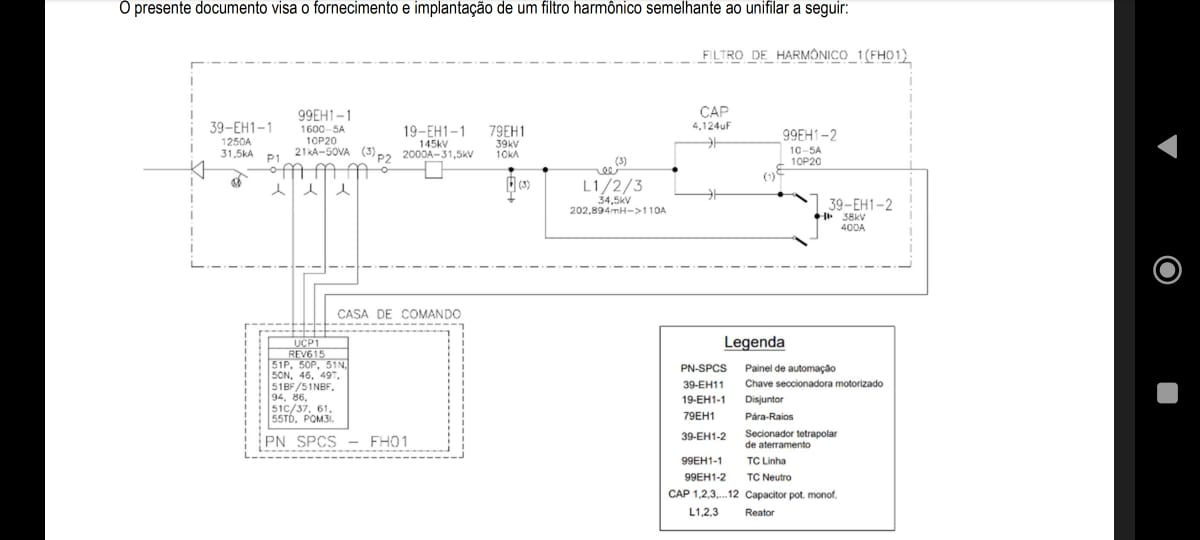

In [14]:
import numpy as np
w1 = 2*np.pi*60

In [15]:
V_fase1 = 34.5e3 / np.sqrt(3)
L = 202.894e-3
C = 4.124e-6
w0 = 1/np.sqrt(L*C)
harmonico_sintonia = w0/w1
Z_indutor1 = 1j*w1*L
Z_capacitor1 = 1/(1j*w1*C)
Z_filtro1 = 2.773 + Z_indutor1 + Z_capacitor1
I_filtro1 = V_fase1 / Z_filtro1
V_fase1 = 34.5e3 / np.sqrt(3)
print(f"Tensão fase-neuro fundamental do filtro = {np.abs(V_fase1)/1e3:.1f} kV")
print(f"Corrente fundamental do filtro = {np.abs(I_filtro1):.2f} A")
print(f"Corrente fundamental do indutor = {np.abs(I_filtro1):.2f} A")
print(f"Corrente fundamental do capacitor = {np.abs(I_filtro1):.2f} A")
print(f"Frequência de sintonia do filtro no harmônico = {harmonico_sintonia:.1f}")

Tensão fase-neuro fundamental do filtro = 19.9 kV
Corrente fundamental do filtro = 35.15 A
Corrente fundamental do indutor = 35.15 A
Corrente fundamental do capacitor = 35.15 A
Frequência de sintonia do filtro no harmônico = 2.9


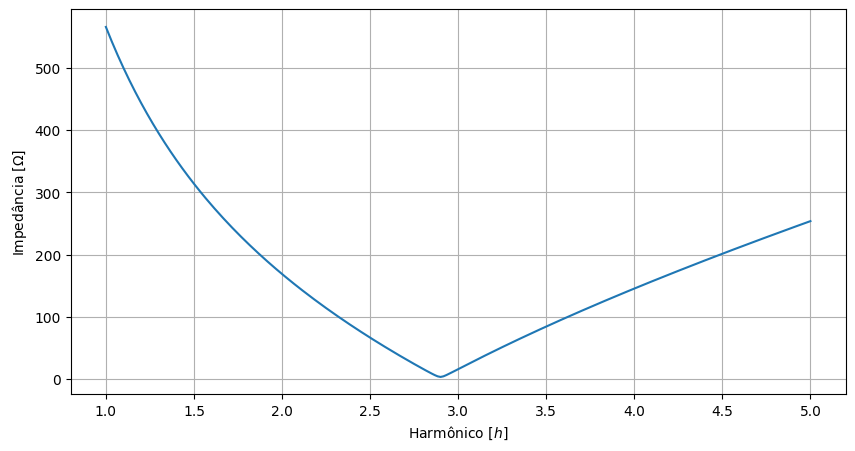

In [16]:
Z_filtro = lambda omega: 2.773 + 1j*omega*L + 1/(1j*omega*C)
f = np.arange(60, 301, 1)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(f/60, np.abs(Z_filtro(2*np.pi*f)))
ax.set_ylabel("Impedância [$\\Omega$]")
ax.set_xlabel("Harmônico [$h$]")
ax.grid(":")

fig.show()

In [17]:
V_banco1 = Z_capacitor1 * I_filtro1
Q_banco1 = 3 * V_banco1 * np.conjugate(I_filtro1)
V_indutor1 = Z_indutor1 * I_filtro1
Q_indutor1 = 3 * V_indutor1 * np.conjugate(I_filtro1)

print(f"Tensão do indutor no harmônico fundamental = {np.abs(V_indutor1)/1e3:.2f} kV")
print(f"Corrente do indutor no harmônico fundamental = {np.abs(I_filtro1):.2f} A")
print(f"Potência consumida pelo indutor no harmônico fundamental = {np.abs(Q_indutor1)/1e6:.2f} MVAr")
print()
print(f"Tensão do Banco de Capacitores no harmônico fundamental = {np.abs(V_banco1)/1e3:.2f} kV")
print(f"Corrente TOTAL do Banco de Capacitores no harmônico fundamental = {np.abs(I_filtro1):.2f} A")
print(f"Potência gerada pelo Banco de Capacitores no harmônico fundamental = {np.abs(Q_banco1)/1e6:.2f} MVAr")
print()
print(f"Potência reativa gerada descontado o consumdo do indutor = {np.abs(Q_banco1+Q_indutor1)/1e6:.1f} MVAr")
print(f"Pra conferir a tensão de fase = {np.abs(V_banco1 + V_indutor1)/1e3:.1f} kV")

Tensão do indutor no harmônico fundamental = 2.69 kV
Corrente do indutor no harmônico fundamental = 35.15 A
Potência consumida pelo indutor no harmônico fundamental = 0.28 MVAr

Tensão do Banco de Capacitores no harmônico fundamental = 22.61 kV
Corrente TOTAL do Banco de Capacitores no harmônico fundamental = 35.15 A
Potência gerada pelo Banco de Capacitores no harmônico fundamental = 2.38 MVAr

Potência reativa gerada descontado o consumdo do indutor = 2.1 MVAr
Pra conferir a tensão de fase = 19.9 kV


In [20]:
V3_mab = 1.15/100 * V_fase1
I_filtro3 = V3_mab / np.real(Z_filtro(2*np.pi*174))
I_estimada_fitro = np.sqrt(I_filtro3**2 + I_filtro1**2)
print(f"Corrente estimada do filtro com harmônicos = {np.abs(I_estimada_fitro):.2f} A")
print(f"Corrente fundamental do filtro = {np.abs(I_filtro1):.2f} A")
print(f"Corrente harmonica (somente harmônica) = {np.abs(I_filtro3):.2f} A") # 1j*100 foi atribuido apenas para cheagar perto do unifilar que estava 110 A


Corrente estimada do filtro com harmônicos = 74.76 A
Corrente fundamental do filtro = 35.15 A
Corrente harmonica (somente harmônica) = 82.61 A
